# NPS Volatility-Conditioned Glide Path — Phase 1 Demo

**Claim:** NPS's default Auto Choice (LC50/LC75) is a fixed, age-based equity/debt/gov-sec glide
path that ignores individual contribution capacity and income volatility. It's a poor fit for
informal-sector workers (gig, small trade, contract labour) whose contribution capacity is irregular
rather than steadily rising with age. This notebook chains the full Phase 1 pipeline end to end:

1. **Real NAV data** — NPS scheme-wise historical returns (E/C/G), SBI + HDFC Tier I
2. **PLFS calibration** — real income-volatility statistics by employment type, from the PLFS Annual
   Report 2023-24
3. **Synthetic income population** — PLFS-calibrated subscriber income/contribution trajectories
4. **PFRDA baseline** — real LC50/LC75 Monte Carlo terminal-corpus distributions
5. **First-cut volatility-conditioned optimizer** — grid-searched glide path vs. the baseline
6. **Honest summary** — what's real data vs. modeling assumption, and this week's most important
   finding

Every step below calls the actual `src/` modules built through the week — nothing here is
reimplemented just for the notebook. Full day-by-day detail: `docs/phase1_status.md`. Full data
provenance: `docs/data_sources.md`. Full PLFS calibration methodology: `docs/plfs_calibration.md`.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display

## 1. Real NAV data

SBI + HDFC Tier I E/C/G, from `npsnav.in` (see `docs/data_sources.md`). SBI's history runs
2009-05 → present (~17 years); HDFC 2013-07 → present (~13 years).

In [2]:
from src.data.clean_nav import summarize

nav_returns = pd.read_parquet("../data/processed/nav_returns.parquet")
summarize(nav_returns)

,pfm,scheme_class,start,end,n_obs,annualized_mean_return,annualized_vol
0,HDFC,C,2013-07-01,2026-08-10,3182,0.089528,0.051621
1,HDFC,E,2013-07-01,2026-08-10,3182,0.135638,0.221781
2,HDFC,G,2013-07-01,2026-08-10,3182,0.084539,0.065887
3,SBI,C,2009-05-05,2026-08-10,4231,0.091961,0.048320
4,SBI,E,2009-05-05,2026-08-10,4231,0.104496,0.201370
5,SBI,G,2009-05-05,2026-08-10,4231,0.086194,0.061282


## 2. PLFS income-volatility calibration

Transcribed from 6 national tables in the PLFS Annual Report 2023-24 (Statements 6/7/10/11/12/14).
Full methodology and every labelled assumption: `docs/plfs_calibration.md`.

In [3]:
calibration = pd.read_csv("../data/processed/plfs_calibration.csv")
calibration

,employment_type,population_share_pct,mean_monthly_income_rs,measured_cross_cell_cv,individual_dispersion_multiplier_assumption,target_individual_cv,volatility_tier
0,regular_salaried,21.7,20702.0,0.2673,1.3,0.3475,low
1,casual_labour,19.8,10032.0,0.2305,2.5,0.5763,medium
2,self_employed,58.4,13279.0,0.5593,2.0,1.1185,high


## 3. Synthetic PLFS-calibrated income population

2,000 synthetic subscribers x 36 years (age 25 to 60 — NPS's standard retirement age), generated from
the calibration table above via cohort assignment, AR(1) temporal shocks, seasonal overlays, and
PLFS-anchored disruption months (see `src/simulation/income_paths.py`). Regenerated fresh here (fixed
seed = reproducible).

In [4]:
from src.simulation.income_paths import simulate_income_paths

income_df = simulate_income_paths()
income_df.to_parquet("../data/processed/synthetic_income_paths.parquet", index=False)

summary = income_df.groupby("employment_type").agg(
    population_share_simulated=("subscriber_id", lambda s: s.nunique() / income_df.subscriber_id.nunique() * 100),
    mean_income=("income", "mean"),
    pct_zero_contribution_months=("contribution", lambda s: (s == 0).mean() * 100),
)
summary

,population_share_simulated,mean_income,pct_zero_contribution_months
employment_type,,,
casual_labour,18.80,22656.281335,10.050360
regular_salaried,22.35,71567.273984,0.066803
self_employed,58.85,44975.253302,10.197969


**The paper's core claim, showing up in the simulation itself, not hardcoded into it:** informal-sector
cohorts (`self_employed`, `casual_labour`) skip contributions in roughly 10% of months, vs. ~0.07% for
`regular_salaried` — a ~150x difference in contribution irregularity, driven entirely by the
PLFS-calibrated volatility and disruption mechanisms.

## 4. PFRDA Auto Choice baseline (LC50 / LC75)

Real, verified age-wise allocation tables (see `docs/data_sources.md` section 4), run through a
block-bootstrap Monte Carlo over SBI's real 207-month NAV return history (2009-2026, the fund's first
calendar month excluded — see `src/simulation/market.py`, it's a fabricated zero-return NFO-period
artifact, not a real market observation), against every synthetic subscriber's real contribution path
over the full 36-year (age 25–60) horizon.

In [5]:
from src.simulation.market import simulate_terminal_corpus, summarize_by_tier

baseline_results = {}
for fund in ["LC50", "LC75"]:
    terminal_corpus, meta = simulate_terminal_corpus(fund=fund, n_market_trials=200)
    baseline_results[fund] = (terminal_corpus, meta)
    print(f"\n=== {fund} ===")
    print(summarize_by_tier(terminal_corpus, meta).to_string())


=== LC50 ===
                       mean      median         p10         p90
volatility_tier                                                
high              8498469.0   6105932.0   1572952.0  17884730.0
low              26352671.0  24976929.0  16224892.0  38252868.0
medium            3078094.0   2702559.0   1126110.0   5460855.0



=== LC75 ===
                       mean      median         p10         p90
volatility_tier                                                
high              8926592.0   6360539.0   1620414.0  18893474.0
low              27605511.0  25962224.0  16507379.0  40743085.0
medium            3235775.0   2810781.0   1158585.0   5795551.0


Note: `medium` tier (`casual_labour`) ends with a *lower* median corpus than `high` tier
(`self_employed`) despite being less volatile — the tier ranks income CV, not income level or
contribution propensity. `self_employed` earns more and contributes a higher share. See Day 5 in
`docs/phase1_status.md` for the full explanation.

## 5. First-cut volatility-conditioned glide-path optimizer

A 3-parameter (equity_start, equity_end, inflection_age) grid search per volatility tier, maximizing
P(terminal corpus >= that tier's own LC50-median target) via the same Monte Carlo engine.

In [6]:
from src.optimization.glide_path_optimizer import run_all_tiers

opt_results = run_all_tiers()
opt_results

,volatility_tier,n_subscribers,target_corpus_rs,lc50_success_prob,lc75_success_prob,optimized_success_prob,optimized_equity_start,optimized_equity_end,optimized_inflection_age
0,low,447,24213554.0,0.5,0.540380,0.626779,0.75,0.3,45
1,medium,376,2617144.0,0.5,0.525492,0.583710,0.75,0.3,45
2,high,1177,5934615.0,0.5,0.516444,0.556924,0.75,0.3,45


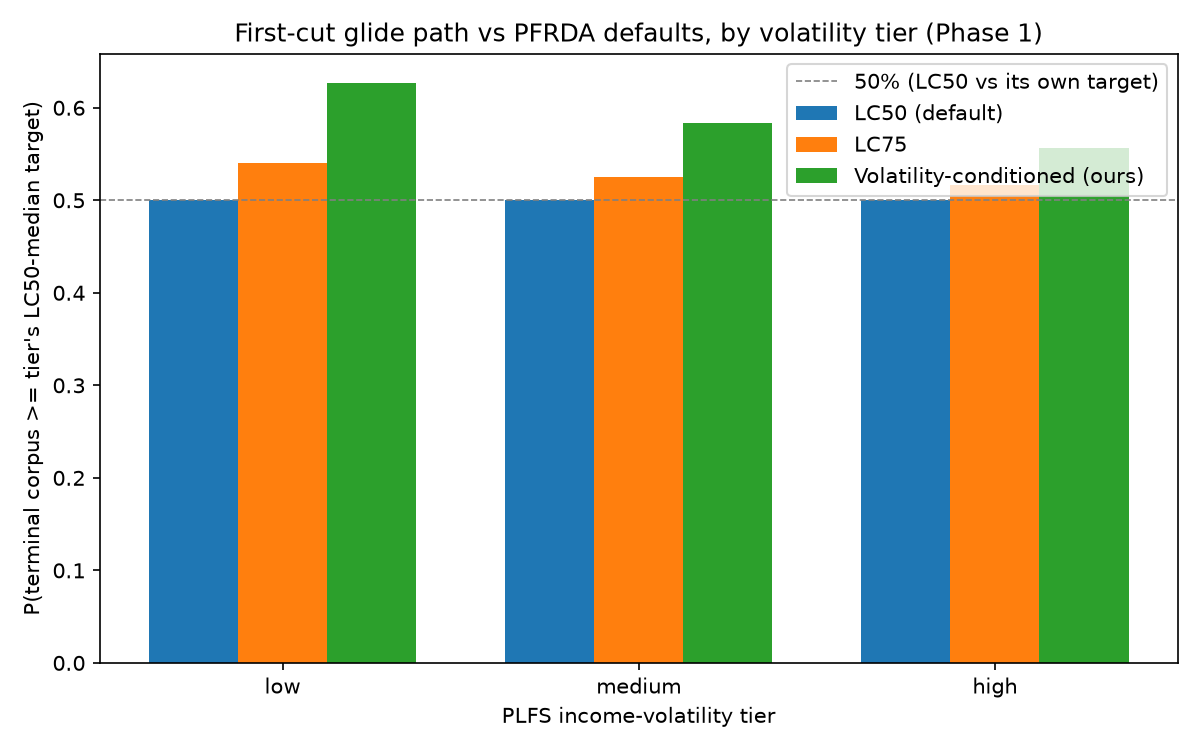

In [7]:
display(Image(filename="../docs/paper/figures/day6_glide_path_comparison.png"))

## 6. Phase 1 summary

**What's real, not fabricated:**
- NAV return series (SBI 2009-2026, HDFC 2013-2026) — real, downloaded, verified
- PLFS employment-type composition, industry composition, quarterly earnings, unemployment rate —
  transcribed directly from the PLFS Annual Report 2023-24's published national tables
- PFRDA LC50/LC75/LC25 allocation tables — verified against a real PFM's investor document, not
  trusted from memory
- The ~150x contribution-skip gap between informal and salaried cohorts — an emergent result of the
  simulation, not hardcoded

**What's a labelled modeling assumption, not measured:**
- The individual-dispersion multiplier that separates PLFS's cell-level CV from an individual-level
  target CV (`docs/plfs_calibration.md`)
- AR(1) persistence, income growth, disruption-rate multipliers, contribution propensity, and the
  subsistence floor (`src/simulation/income_paths.py` docstring)
- The corporate-debt/gov-securities split of the optimizer's non-equity remainder (fixed, not
  optimized, in Phase 1)

**This week's most important finding, and it's a limitation, not a clean win:** the first-cut
optimizer picks the *same* near-max-equity glide path for all three volatility tiers — it does not
yet show the tier-differentiated glide paths that are the paper's central claim. Diagnosed across four
different target/utility formulations (median target, P75 target, CVaR-10%, and a tier-independent
floor target): all are monotonically increasing in equity exposure, for every tier, because the real
2009-2026 bootstrap window's realized equity risk premium is strong enough that even worst-decile
outcomes still favour more equity. **This was re-tested, not assumed, after extending the horizon from
30 to 36 years specifically so the simulation would reach and exercise PFRDA's own "55 & above"
plateau** (the most conservative, de-risked part of every Auto Choice schedule, previously never
reached at a 30-year/age-54 horizon) — the finding held: still the identical glide path for every
tier, even once the retirement-adjacent de-risking years are included. This means the differentiator
the paper needs is likely **intra-horizon shortfall/sequence risk**, not terminal-wealth distribution
shape — motivating Phase 2 Week 1's planned CVaR-adjusted objective, and pointing toward an explicitly
shortfall-sensitive utility as the next concrete step. Full diagnostic detail:
`docs/phase1_status.md`, Day 6.

**Also fixed during this review pass, before finalizing Phase 1:** the Monte Carlo bootstrap source had
a small but real bug — a `.dropna()` that didn't actually drop a fabricated zero-return "month" from
SBI's May 2009 fund-launch period (NAV was pegged flat, so daily returns were 0.0, not NaN, and
survived the intended filter). Fixed by excluding the fund's first calendar month explicitly; every
number in this notebook reflects the corrected 207-month bootstrap pool. See `docs/eval_day_guide.md`
for the full story.